# STUAART: Validation pipeline

This notebook is designed to process, synchronize, and validate time-series mass data collected from the **STUAART** automated cage system. The primary goal is to transform raw CSV data into a continuous, analyzed dataset while assessing the system's accuracy against manual ground-truth measurements.

The script follows a structured workflow to ensure data integrity:
1.  Environment Setup: Loading dependencies (`NumPy`, `Pandas`, `Matplotlib`, etc.).
2.  Configuration: Setting directory paths and inputting manual ground-truth data.
3.  Synchronization: Mounting Google Drive and aligning experimental timestamps.
4.  Extraction: Aggregating daily fragmented CSV files into a single continuous array.
5.  Metrics Calculation:
    * MAE & RMSE: Quantifying weighing accuracy.
    * SNR & CV: Measuring signal noise and precision.
    * Pearson Correlation ($r$): Validating trend sensitivity and ground-truth alignment.
    * Completeness: Checking for hardware uptime and potential data loss.
6.  Visualization: Generating a 1:1 validation scatter plot to detect calibration biases.

## Quick Start

In Cell 2,
1. Ensure your data is organized in the specified `project_directory`.
2. If you want to save the values of the metrics, set `save_data` to True and modify `saved_filename` to your preferred name.
3.  Update `delta_t` to define the time window in which the metrics are computer around the real mass.  
4.  Update the `manual_mass` list with your reference measurements: `(day, time, mass_in_grams)`.

Finally, run all cells to generate the validation report and save the processed metrics.

In [29]:
import numpy as np
from numpy._core.numeric import indices
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path
from scipy.ndimage import uniform_filter1d, label

# Configuration and Manual Ground Truth

This cell is used to define global variables, file paths, and experimental parameters. This section includes the manual_mass list, which serves as the ground truth (reference measurements) to validate the automated system.

In [30]:
# Change these variables
project_directory = "/content/drive/My Drive/DCCM_Lab/labdata/vpineaunoel/stuaart"
data_path = project_directory + "/20260730-3MiceInSTUAARTs_5/Red/WithoutBufferFlushes/"
save_data = True
debug_mode = False
time_is_in_hour = True
time_acquired_with_millis = False
threshold_outliers = 50
sampling_rate = 80
delta_t = 2
saved_filename = "2026.07.30-RedSTUAART-" + str(delta_t) + "WithoutHangingMoments-Raw-metrics.csv"

# Add in the list the real mass measurements done during the experiment.
# Format : (day, time, mass)
manual_mass = [
    (1, "13:52", 24.1),
    (1, "16:28", 23.8),
    (2, "10:00", 25.2),
    (2, "16:03", 24.7),
    (3, "10:00", 26.2),
    (4, "10:00", 23.0),
    (4, "15:00", 25.4),
    (5, "8:50", 26.1),
    (5, "12:55", 26.0),
    (6, "8:41", 25.8)
    ]

# Google Drive Integration

This cell mounts Google Drive to the Colab environment and set the working directory to the project folder for seamless file access.

In [31]:
from google.colab import drive
drive.mount('/content/drive/')
import os
os.chdir(project_directory)

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


# Data Processing Functions

This cell defines the core logic for the STUAART data pipeline. These functions handle the transition from raw, fragmented CSV files to a synchronized and validated time-series dataset.

- `identify_all_days_of_experiment()`: Scans the data directory to extract dates from filenames and assigns a relative day index (e.g., Day 1, Day 2) to maintain a chronological sequence.
- `str_to_float_hour()`: Converts standard "HH:MM" or relative float/int timestamps into a decimal format (float) for easier mathematical operations.
- `compute_start_shift()`: Determines the time offset by analyzing the duration of the first data file. This ensures that the data aligns correctly with a 24-hour cycle, regardless of when the experiment started.
- `extract_data_from_all_days()`: The primary aggregation engine. It iterates through all daily files, converts millisecond timestamps to hours, applies the start shift, and concatenates the mass data from multiple scales into a single continuous array.
- `format_manual_mass()`: Synchronizes the manual ground-truth measurements with the script's internal timeline. It handles both date-based and relative day inputs to ensure the validation metrics are calculated at the exact correct moment in the series.
- `sum_data_over_time()`: Sums mass from individual scales at every timepoint to calculate the total mass within the cage environment.
- `compute_sampling_frequency()` :

In [32]:
def identify_all_days_of_experiment(data_path, debug_mode):
  """
  Extracts experiment dates and relative day indices from CSV filenames.

  Args:
      data_path (str): Directory containing .csv files named 'YYYYMMDD-...'.
      debug_mode (bool): If True, prints mapping results.

  Returns:
      tuple: (list of date strings, list of relative day integers).
  """
  files = os.listdir(data_path)
  files.sort()

  dates_of_experiment = []
  relative_days_of_experiment = []

  i = 1
  for file in files: # put in order the dates of the experiments based on the beginning of the CSV file names.
    if file.endswith(".csv"):
      index_first_dash = file.find("-")
      dates_of_experiment.append(file[:index_first_dash])
      relative_days_of_experiment.append(i)
      i += 1

  if debug_mode:
    print("Dates of experiment : ", dates_of_experiment)
    print("Relative days of experiment : ", relative_days_of_experiment)

  return dates_of_experiment, relative_days_of_experiment


def str_to_float_hour(time_str):
  """
  Converts str hour in the format 00:00 to a float value
  """
  hours, minutes = map(int, time_str.split(':'))
  return hours + (minutes / 60.0)


def compute_start_shift(data_path, debug_mode, time_is_in_hour:bool = False):
  """
  Calculates the time offset required to align experimental data with a 24-hour clock.

  Args:
      data_path (str): Directory containing the experimental CSV files.
      debug_mode (bool): If True, prints file paths and the calculated shift.

  Returns:
      float: The start shift in hours to be added to the time series.
  """
  files = os.listdir(data_path)
  files.sort()
  absolute_first_file = data_path + files[0]
  first_data = pd.read_csv(absolute_first_file)
  if time_is_in_hour:
    first_duration = first_data.iloc[-1, 0]
  else:
    first_duration = first_data.iloc[-1, 0] / (1000 * 60 * 60)
  start_shift = (24.0 - first_duration) % 24

  if debug_mode:
    print("Data path : ", data_path)
    print("Path first day : ", absolute_first_file)
    print("Data first day : ", first_data)
    print("Start shift : ", start_shift)

  return start_shift


def extract_data_from_all_days(data_path, start_shift, debug_mode, time_is_in_hour:bool = False, time_acquired_with_millis:bool = True):
  """
  Aggregates mass data from all daily CSV files into a continuous time series.

  Args:
      data_path (str): Path to the folder containing daily data files.
      start_shift (float): Time offset in hours calculated for the first day.
      debug_mode (bool): If True, prints shape and range of the concatenated data.

  Returns:
      tuple: (time_hour array, mass_data array) representing the full experiment.
  """
  all_time_hour = []
  all_mass_data = []

  files = os.listdir(data_path)
  files.sort()
  for file in files:
    if file.endswith(".csv"):
      file_path = data_path + file
      data = np.array(pd.read_csv(file_path))
      time = data[:,0]
    else:
      continue

    if time_is_in_hour:
      current_time_hour = time
    else:
      current_time_hour = time/(1000 * 60 * 60)

    current_mass_data = data[:, 1:]
    if time_acquired_with_millis:
      start_shift = compute_start_shift(data_path=data_path, debug_mode=debug_mode, time_is_in_hour=time_is_in_hour)
      current_time_hour = (start_shift + current_time_hour)

    all_time_hour.append(current_time_hour)
    all_mass_data.append(current_mass_data)

  # all data is contained in time_hour and mass_data after these two lines
  time_hour = np.concatenate(all_time_hour)
  mass_data = np.concatenate(all_mass_data, axis=0)

  if time_acquired_with_millis is False:
    diffs = np.diff(time_hour)
    rollover_next_day = diffs < -12.0
    rollovers = np.concatenate(([False], rollover_next_day))
    days_passed = np.cumsum(rollovers)
    time_hour = time_hour + (days_passed * 24.0)

  if debug_mode:
    print(f"Beginning {time_hour[0]} an end {time_hour[-1]} value of time overall.")
    print("Time_hour : ", time_hour, time_hour.shape)
    print(f"Mass data : {mass_data} {mass_data.shape}")

  return time_hour, mass_data


def format_manual_mass(manual_mass, dates_of_experiment, relative_days_of_experiment, start_shift, debug_mode):
  """
  Synchronizes manual ground-truth measurements with the continuous experimental timeline.

  Args:
      manual_mass (list): List of tuples (day, time, mass) to be synchronized.
      dates_of_experiment (list): List of date strings from filenames.
      relative_days_of_experiment (list): List of sequential day integers.
      start_shift (float): Time offset in hours for the first day.
      debug_mode (bool): If True, prints the formatted timestamps and masses.

  Returns:
      list: Formatted tuples (continuous_time_hour, mass) for system validation.
  """
  if manual_mass is None:
    return None
  else:
    new_manual_mass = []
    for m_day, m_time, m_mass in manual_mass:
      if isinstance(m_day, (int, float)):
        new_day = relative_days_of_experiment[m_day-1]
      elif isinstance(m_day, str):
        new_day = dates_of_experiment.index(m_day) + 1

      if isinstance(m_time, str):
        time_in_float = str_to_float_hour(m_time)
      else:
        time_in_float = m_time + start_shift

      new_time = time_in_float + ((new_day-1) * 24)
      new_manual_mass.append((new_time, m_mass))

  if debug_mode:
    print("Real mass after formatting : ", new_manual_mass)

  return new_manual_mass


def sum_data_over_time(data_per_scale):
  """
  Sum data per time point to obtain the mass measurement over time of the whole cage system (and not only per scale).
  """
  summed_data = np.nansum(data_per_scale, axis=1)
  return summed_data


def compute_sampling_rate(time_in_hours):
	"""
	Computes the sampling rate according to the time array.
	"""
	time_in_seconds = time_in_hours*60*60

	dt = np.diff(time_in_seconds)
	# Compute the average sampling rate
	fs_mean = 1 / np.mean(dt)

	# You can also check the variability:
	fs_std = np.std(1 / dt)

	print(f"Estimated mean sampling rate: {fs_mean:.3f} Hz")
	print(f"Standard deviation of sampling rate: {fs_std:.3f} Hz")
	print(f"Min: {1/np.max(dt):.3f} Hz, Max: {1/np.min(dt):.3f} Hz")

	return fs_mean, fs_std


def convolution_filter_with_padding_edge(data, length: int=10, iteration: int=1, kernel_type: str="average"):
  """ High-pass convolution filter on the signal. This filter is meant to smooth up the signal
  and remove outliers without any threshold. The edges are padded to correct for boundary effects.
  Arguments:
  - length: length of the kernel to convolve on signal. default is 10
  - iteration: number of consecutive convolutions to do. default is 1
  - kernel_type : either average or high-pass
  """
  # raise an error if number of iteration is not possible
  if iteration <= 0:
    raise ValueError("Number of iteration cannot be under 1")

  input_data_length = data.shape[0]
  current_data = data.copy()

  if kernel_type == 'average':
    for _ in range(iteration):
      valid_mask = ~np.isnan(current_data)
      data_filled = np.nan_to_num(current_data, nan=0.0)

      # Vectorized across all scales at once using axis=0
      moving_sum = (uniform_filter1d(data_filled, size=length, axis=0, mode='nearest') * length)
      moving_count = (uniform_filter1d(valid_mask.astype(float), size=length, axis=0, mode='nearest') * length)

      with np.errstate(divide='ignore', invalid='ignore'):
        current_data = moving_sum / moving_count
        current_data[moving_count == 0] = np.nan

    return current_data

  elif kernel_type == "high-pass" :
    filtering_array = np.array([-1, -1, 0, 0, 0, 0, 0, 1, 1])  # High-pass filter
    pad_width = len(filtering_array) // 2  # Automatically 4
    current_data = data.copy()

    for i in range(iteration):
      # Pad current_data (not original data) using mean mode
      padded_data = np.pad(current_data, pad_width, mode='mean')
      convolved_data = np.convolve(padded_data, filtering_array, mode='same')

      # Slice back using pad_width to match kernel size precisely
      current_data = convolved_data[pad_width : pad_width + input_data_length]

    return current_data


def compute_hanging(time, summed_data, sampling_rate: int, threshold: int = 5, bins: float = 0.5, first_day: bool = False):
  """
  Hanging is when the mass data drops below the threshold for more than 1 second.
  A convolution is done with an average filter to smooth the data.
  Contiguous blocks below the threshold are identified using region labeling.
  Calculates hanging moments, total time hanging per bin, and hanging frequency per bin.
  """
  # Smooth the data using the average filter
  avg_conv_data = convolution_filter_with_padding_edge(data=summed_data, length=15, kernel_type="average")

  # Direct threshold masking: find all points where smoothed mass drops below threshold
  is_low_mass = (avg_conv_data < threshold)

  # Label contiguous blocks of low mass (connected components)
  labeled_array, num_features = label(is_low_mass)

  start_indices = []
  end_indices = []
  hanging_moments = np.zeros(shape=time.shape)

  # Time conversion constants (since 'time' is in decimal hours)
  min_duration_hours = 1.0 / 3600.0        # 1 second in hours
  max_duration_hours = 180.0 / 3600.0      # 3 minutes in hours

  for region_id in range(1, num_features + 1):
    indices = np.where(labeled_array == region_id)[0]
    if len(indices) == 0:
      continue

    start = indices[0]
    end = indices[-1]
    duration = time[end] - time[start]

    # Filter by physical duration limits (1 second to 3 minutes)
    if min_duration_hours <= duration <= max_duration_hours:
      start_indices.append(start)
      end_indices.append(end)
      hanging_moments[start:end + 1] = 1  # end + 1 to include the endpoint

  start_indices = np.array(start_indices)
  end_indices = np.array(end_indices)

  # Handle first day exclusion
  if first_day and len(start_indices) > 0:
    time_when_mouse_is_in = when_mouse_is_in(time=time, data=summed_data, sampling_rate=sampling_rate)
    index_when_mouse_is_in = np.argmin(np.abs(time - time_when_mouse_is_in))
    valid_mask = start_indices >= index_when_mouse_is_in
    start_indices = start_indices[valid_mask]
    end_indices = end_indices[valid_mask]
    hanging_moments[:index_when_mouse_is_in] = 0

  # Get start and end times of validated bouts
  start_hanging = time[start_indices] if len(start_indices) > 0 else np.array([])
  end_hanging = time[end_indices] if len(end_indices) > 0 else np.array([])

  # Define bin edges consistently
  bin_edges = np.arange(time[0], time[-1] + bins, bins)

  hanging_frequency = []
  hanging_time_per_bin = []

  # Integrate overlap of each bout with each time bin window [bin_start, bin_end)
  for bin_start, bin_end in zip(bin_edges[:-1], bin_edges[1:]):
    if len(start_hanging) == 0:
      hanging_frequency.append(0)
      hanging_time_per_bin.append(0.0)
      continue

    # Count bouts whose start time falls inside the bin
    bouts_started = np.count_nonzero((start_hanging >= bin_start) & (start_hanging < bin_end))
    hanging_frequency.append(bouts_started)

    # Compute duration overlap for bouts spanning or falling within this bin
    # Overlap = max(0, min(bout_end, bin_end) - max(bout_start, bin_start))
    overlap_starts = np.maximum(start_hanging, bin_start)
    overlap_ends = np.minimum(end_hanging, bin_end)
    overlaps = np.maximum(0.0, overlap_ends - overlap_starts)

    total_bin_time = float(np.sum(overlaps))
    hanging_time_per_bin.append(total_bin_time)

  hanging_frequency = np.array(hanging_frequency)
  hanging_time_per_bin = np.array(hanging_time_per_bin)

  return hanging_moments, hanging_time_per_bin, hanging_frequency


# Execution of Data Pipeline

After definind all the functions we need, we use them to clean, align, and merge the datasets. This transforms raw, fragmented files into a single continuous time series of total mass (`summed_data`) and a synchronized reference list (`formatted_manual_mass`).

In [33]:
dates_of_experiment, relative_days_of_experiment = identify_all_days_of_experiment(data_path=data_path, debug_mode=debug_mode)
start_shift = compute_start_shift(data_path=data_path, debug_mode=debug_mode, time_is_in_hour=time_is_in_hour)
time_hour, mass_data = extract_data_from_all_days(data_path=data_path, start_shift=start_shift, debug_mode=debug_mode, time_is_in_hour=time_is_in_hour, time_acquired_with_millis=time_acquired_with_millis)
formatted_manual_mass = format_manual_mass(manual_mass=manual_mass, dates_of_experiment=dates_of_experiment, relative_days_of_experiment=relative_days_of_experiment, start_shift=start_shift, debug_mode=debug_mode)
summed_data = sum_data_over_time(data_per_scale=mass_data)
mean_sampling_rate, std_sampling_rate = compute_sampling_rate(time_in_hours=time_hour)

Estimated mean sampling rate: 77.677 Hz
Standard deviation of sampling rate: 13.707 Hz
Min: 0.021 Hz, Max: -1.002 Hz


# Validation Metrics and Performance Analysis

This cell calculate key performance indicators to assess the accuracy and reliability of the automated weighing system:

- **Accuracy:** Mean Absolute Error (MAE) and Root Mean Square Error (RMSE).
  - **MAE**: On average, tells how many grams off the STUAART is compared to the ground truth mass.
  - **RMSE**: While MAE treats all errors equally, RMSE penalizes larger outliers more heavily.
- **Precision/Noise:** Coefficient of Variation (CV) and Signal-to-Noise Ratio (SNR).
  - **CV**: Defines the variation of the data compared to the mean.
  - **SNR**: Characterizes the variation around the mean. A high SNR indicates a lot of noise.
- **Trend Correlation:** Pearson’s $r$ (System sensitivity to mass changes). This measures the linear relationship over the entire timeline. Even if there is a slight offset in accuracy, it confirms the system catches mass loss and gain trends.
- **System Validation ($r$):** The Pearson correlation specifically between **manual ground truth** and **automated readings**. This directly validates that the system accurately reflects the animal's true mass at specific validation points.
- **Reliability (Completeness):** Defines how much data was actually acquired compared to how much should be acquired based on the sampling rate. A robust system stays above 95%.
- **Sampling rate :** The computed sampling rate from the data.  

Finally, it generates a scatter plot of the ground truth mass values vs. the measured mass of the system. The proximity of data points to the 1:1 dashed line visually confirms the system's calibration and identifies potential bias.

time and mass :  13.866666666666667 24.1
time_range :  (11.866666666666667, 15.866666666666667)
Indices in time range :  [     0      1      2 ... 562796 562797 562798]
The percentage of outliers (threshold = 50) : 0.130597 %.
time and mass :  16.466666666666665 23.8
time_range :  (14.466666666666665, 18.466666666666665)
Indices in time range :  [ 168096  168097  168098 ... 1295039 1295040 1295041]
The percentage of outliers (threshold = 50) : 0.124673 %.
time and mass :  34.0 25.2
time_range :  (32.0, 36.0)
Indices in time range :  [5100387 5100388 5100389 ... 6220868 6220869 6220870]
The percentage of outliers (threshold = 50) : 0.116200 %.
time and mass :  40.05 24.7
time_range :  (38.05, 42.05)
Indices in time range :  [6793677 6793678 6793679 ... 7911276 7911277 7911278]
The percentage of outliers (threshold = 50) : 0.190050 %.
time and mass :  58.0 26.2
time_range :  (56.0, 60.0)
Indices in time range :  [11817122 11817123 11817124 ... 12935608 12935609 12935610]
The percentage o

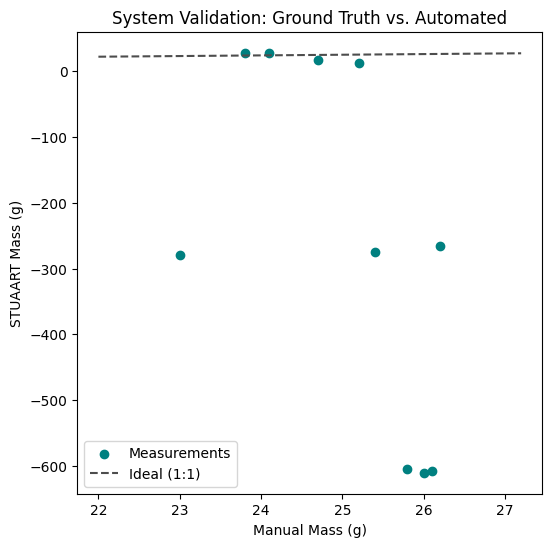

In [34]:
path = Path(data_path)
new_path = path.parent / "Metrics"
new_path.mkdir(parents=True, exist_ok=True)

# Compute MAE, RMSE, CV and SNR
all_MAEs = []
all_CVs = []
all_RMSEs = []
all_SNRs = []
all_MAPEs = []
all_Ns = []
stuaart_measurement_at_manual_time = []
manual_mass_values = []
for m_time, m_mass in formatted_manual_mass:
  print("time and mass : ", m_time, m_mass)
  time_range = (m_time-delta_t, m_time+delta_t)
  print("time_range : ", time_range)
  indices_in_time_range = np.where((time_hour >= time_range[0]) & (time_hour <= time_range[1]))[0]
  data_in_time_range = summed_data[indices_in_time_range]
  time_in_time_range = time_hour[indices_in_time_range]

  print("Indices in time range : ", indices_in_time_range)

  if indices_in_time_range.shape[0] == 0:
    continue

  # mass data during hanging moments are removed to better estimate the animal's mass
  hanging_moments, total_time_hanging, hanging_frequency = compute_hanging(time=time_in_time_range, summed_data=data_in_time_range, sampling_rate=sampling_rate)
  data_in_time_range = data_in_time_range[hanging_moments == 0]

  stuaart_measurement_at_manual_time.append(np.nanmean(data_in_time_range))
  manual_mass_values.append(m_mass)

  indices_of_outliers = np.where(np.abs(data_in_time_range - m_mass) > threshold_outliers)
  percentage_of_outliers = indices_of_outliers[0].shape[0] / indices_in_time_range.shape[0] * 100
  print(f"The percentage of outliers (threshold = {threshold_outliers}) : {percentage_of_outliers:3f} %.")

  if debug_mode:
    print("DEBUG ------------------------------")
    print(f"m_time : {m_time}, {type(m_time)} and m_mass : {m_mass}, {type(m_mass)}")
    print("Time hour : ", time_hour, time_hour.shape, type(time_hour[0]))
    print("Time range : ", time_range, type(time_range[0]))
    print("Indices in time range : ", indices_in_time_range)
    print("Data in time range : ", data_in_time_range, data_in_time_range.shape)
    print("DEBUG ------------------------------")

  MAE = np.nanmean(np.abs(data_in_time_range - m_mass))
  all_MAEs.append(MAE)
  MAPE = MAE/m_mass*100
  all_MAPEs.append(MAPE)
  CV = (np.nanstd(data_in_time_range) / np.nanmean(data_in_time_range)) * 100
  all_CVs.append(CV)
  RMSE = np.sqrt(np.nanmean((data_in_time_range - m_mass)**2))
  all_RMSEs.append(RMSE)
  SNR = np.nanmean(np.absolute(data_in_time_range)) / np.nanstd(data_in_time_range)
  all_SNRs.append(SNR)
  N = data_in_time_range.shape[0]
  all_Ns.append(N)

print("A good MAE is close to 0 g.")
print(f"Mean Absolute Error (MAE) : {np.mean(all_MAEs):3f} computed from {all_MAEs}.")
print("MAPE is the MAE divided by the refenbrence value. Relative MAE * 100.")
print(f"Mean Absolute Percentage Error (MAPE) : {np.mean(all_MAEs):3f} computed from {all_MAPEs}.")
print("A good CV is typically < 1-2 %.")
print(f"Coefficient of variation (CV) : {np.mean(all_CVs):3f} computed from {all_CVs}.")
print("A good RMSE is close to 0 g.")
print(f"Root Mean Square Error (RMSE) : {np.mean(all_RMSEs):3f} computed from {all_RMSEs}.")
print("A high SNR indicates a lot of noise.")
print(f"Signal-to-noise ratio (SNR) : {np.mean(all_SNRs):3f} computed from {all_SNRs}.")

# Compute Pearson's
matrix = np.corrcoef(time_hour, summed_data)
corr = matrix[0,1]

print("A Pearson's correlation close to 1.0 indicates the system catches mass trends well.")
print(f"Pearson's correlation (r) : {corr:3f}")

# Pearson correlation between manual truth and automated measurement
validation_matrix = np.corrcoef(manual_mass_values, stuaart_measurement_at_manual_time)
r_validation = validation_matrix[0, 1]

print(f"System Validation Correlation (r): {r_validation:3f}")

# Compute completeness/Sparsity
total_experimental_time_hour = time_hour[-1] - time_hour[0]
N_total = sampling_rate * 3600 * total_experimental_time_hour
N_actual = summed_data.shape[0]

completeness = N_actual/N_total * 100

print("A robust system has a completeness of >95%. If it is lower, it suggests the system is crashing or the hardware is disconnecting.")
print(f"Completeness : {completeness:3f}")

print(f"The sampling rate compute from the data is : {mean_sampling_rate:3f} +- {std_sampling_rate:3f}.")


plt.figure(figsize=(6,6))
plt.scatter(manual_mass_values, stuaart_measurement_at_manual_time, color='teal', label='Measurements')
plt.plot([min(manual_mass_values)-1, max(manual_mass_values)+1],
         [min(manual_mass_values)-1, max(manual_mass_values)+1],
         ls="--", c=".3", label="Ideal (1:1)")
plt.xlabel("Manual Mass (g)")
plt.ylabel("STUAART Mass (g)")
plt.title("System Validation: Ground Truth vs. Automated")
plt.legend()
if save_data:
  plt.savefig(new_path / (saved_filename[:-4] + "_validation_figure.png"), transparent=True)
plt.show()


# Export Results

Finally, this cell consolidate the calculated metrics into a summary table and save the results as a CSV file in your project directory for further longitudinal analysis.

In [35]:
if save_data:
  parent_dir = os.path.dirname(os.path.normpath(data_path))

  metrics = {"Delta time [hour]" : delta_t,
             "Real mass [g]": manual_mass_values,
             "STUAART mass [g]" : stuaart_measurement_at_manual_time,
             "Number of data points" : all_Ns,
             "Mean absolute error (MAE) [g]" : all_MAEs,
             "Mean absolute percentage error [%]" : all_MAPEs,
             "Coefficient of Variation" : all_CVs,
             "Root mean square error (RMSE) [g]" : all_RMSEs,
             "Signal-to-noise ration (SNR)" : all_SNRs}
  metrics_df = pd.DataFrame(metrics)
  metrics_df.to_csv(new_path / (saved_filename[:-4] + "_IndividualData.csv"), index=False)

  mean_metrics = {"Metrics" : ["Mean value", "Standard deviation"],
                  "Delta time [hour]" : [delta_t, "-"],
                  "Mean absolute error (MAE) [g]" : [np.mean(all_MAEs), np.std(all_MAEs)],
                  "Mean absolute percentage error (MAPE) [%]" : [np.mean(all_MAPEs), np.std(all_MAPEs)],
                  "Coefficient of Variation" : [np.mean(all_CVs), np.std(all_CVs)],
                  "Root mean square error (RMSE) [g]" : [np.mean(all_RMSEs), np.std(all_RMSEs)],
                  "Signal-to-noise ratio (SNR)" : [np.mean(all_SNRs), np.std(all_SNRs)],
                  "Pearson's correlation (r)" : [corr, "-"],
                  "System Validation Correlation (r)" : [r_validation, "-"],
                  "Completeness [%]" : [completeness, "-"],
                  "Sampling rate [Hz]" : [mean_sampling_rate, std_sampling_rate],
                  f"Percentage of outliers [%] with threshold at {threshold_outliers}" : [percentage_of_outliers, "-"]
                  }
  mean_metrics_df = pd.DataFrame(mean_metrics, index=[0, 1])

  saved_path = new_path / saved_filename
  print(f"Your data was saved at {saved_path}.")
  mean_metrics_df.to_csv(saved_path, index=False)

Your data was saved at /content/drive/My Drive/DCCM_Lab/labdata/vpineaunoel/stuaart/20260730-3MiceInSTUAARTs_5/Red/Metrics/2026.07.30-RedSTUAART-2WithoutHangingMoments-Raw-metrics.csv.
